# Company A (US Wireless Telecom): Churn Prevention & High-Value Retention PoC

**Author:** Jose Alonso Yanez Mejia  
**Competition / Assignment:** GCI World 2026 Final Assignment  
**Objective:** Build an end-to-end, leakage-free machine learning pipeline to predict subscriber churn (31–60 days post-observation), uncover intervenable operational drivers, and quantify a targeted retention strategy with positive 6-month and 12-month ROI.

---

### Notebook Structure
1. **Introduction & US Telecom Market Context** — Industry benchmarks, competitive landscape, unit economics, and framing Company A's problem.
2. **Data Loading & Merging** — Reproducible ingestion and 1:1 inner join of `Client.csv` and `Record.csv`.
3. **Exploratory Data Analysis (EDA)** — Data quality audit, missingness, target balance, revenue at risk, and intervenable segment deep-dives.
4. **Problem Definition & Leakage-Free Feature Engineering** — Anomaly handling, 13 domain-driven features, stratified 80/20 split, and `sklearn` Pipeline preprocessing.
5. **Multi-Model Experiments & Evaluation** — 5-fold Stratified CV & held-out Test comparison across Logistic Regression, Random Forest, LightGBM, and XGBoost; threshold tuning; risk quintile/decile lift; and feature importance.
6. **Quantified Business Proposal & 90-Day Pilot** — Two-Tier Retention Architecture, 6m/12m ROI, break-even & sensitivity analysis, A/B pilot design, and risk mitigation.

## 1. Introduction & US Wireless Telecom Market Context

### 1.1 Business Problem
Customer attrition is one of the largest value-destruction levers in US wireless telecommunications. Company A's analytical dataset (`100,000` subscribers) exhibits a **`49.56%` churn rate** in the 31–60 day post-observation window (representing a balanced PoC sample), putting **`$2.87M/month` (`$34.45M/year`)** in recurring service revenue at risk. Deploying an untargeted, blanket retention discount across all `100,000` subscribers is capital-inefficient because roughly half of the base would remain without intervention. Our goal is to replace blanket discounting with a **targeted, value-matched retention program** powered by predictive churn modeling and intervenable behavioral triggers.

### 1.2 US Wireless Market Landscape & Benchmarks (2024–2026)
External industry benchmarks frame both the urgency and unit economics of Company A's retention challenge:

* **Market Size & Concentration:** Total US telecom services revenue is valued at **`$450B–$470B`** across 2024–2025, growing at a **`5.8%–7.9%` CAGR** driven by 5G adoption, Fixed Wireless Access (FWA), and IoT connectivity [1, 2]. The "Big Three" facilities-based carriers control **~95%** of major postpaid share—**T-Mobile (~35%)**, **Verizon (~34%)**, and **AT&T (~27%)**—while Cable MVNOs (e.g., Xfinity Mobile, Spectrum Mobile) and value brands increasingly capture price-sensitive subscribers [3, 4].
* **Churn Rate Benchmarks:** Tier-1 US postpaid phone churn operates in a tight **`0.7%–1.1%` per month** band (**~8%–13% annualized**; e.g., T-Mobile `~0.93%` and AT&T `~0.98%` in 2025), whereas prepaid and non-contract tiers experience **`2.5%–3.8%` per month** (**~30%–37% annualized**) [5, 6].
* **Unit Economics (CAC vs. Retention):** Broad telecom Customer Acquisition Cost (CAC) averages **`$250–$400` per subscriber**—and scales to **`$400–$600+`** for fully-loaded postpaid phone acquisitions with device subsidies—compared to just **`$15–$35` per user** for targeted retention [7]. Meanwhile, US postpaid phone ARPU averages **`~$53–$54+/month`** (with multi-line ARPA at `$150–$170+/month`) [2].
* **Operational Churn Drivers:** J.D. Power's 2026 U.S. Wireless Customer Care Study shows that **ease of doing business** separates loyal customers (`786/1,000` satisfaction) from high-effort detractors (`554/1,000`), with **`<10-minute` resolution** acting as a major retention advantage while **`20%–25%` call transfer rates** sharply elevate switching intent [8]. Billing/overage shocks and Equipment Installment Plan (EIP) / handset upgrade milestones represent the primary actionable windows for proactive intervention [8, 9].

## 2. Data Loading & Merging

We load `Client.csv` (account, demographic, and device attributes) and `Record.csv` (billing, usage, and network/care call metrics) from `Final Assignment/telecom/` using relative paths, and perform an inner join on `Customer_ID`.

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    recall_score,
    precision_score,
    f1_score,
    accuracy_score,
    roc_curve,
    precision_recall_curve,
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")

# Reproducibility & global plotting style
RANDOM_STATE = 42
DATA_DIR = os.path.join("Final Assignment", "telecom")
CLIENT_PATH = os.path.join(DATA_DIR, "Client.csv")
RECORD_PATH = os.path.join(DATA_DIR, "Record.csv")

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.color": "#EEEEEE",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "axes.axisbelow": True,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

NAVY = "#1B365D"
TEAL = "#008080"
CORAL = "#D9534F"
AMBER = "#E69F00"
SLATE = "#5C6B73"
LIGHT_BLUE = "#4A90D9"

print("Environment configured successfully.")

Environment configured successfully.


In [2]:
client = pd.read_csv(CLIENT_PATH)
record = pd.read_csv(RECORD_PATH)

overlap_cols = sorted(set(client.columns) & set(record.columns))
df = client.merge(record, on="Customer_ID", how="inner")

print(f"Client shape: {client.shape} | Unique Customer_ID: {client['Customer_ID'].nunique():,}")
print(f"Record shape: {record.shape} | Unique Customer_ID: {record['Customer_ID'].nunique():,}")
print(f"Overlapping columns: {overlap_cols}")
print(f"Merged shape: {df.shape} | Exact duplicate rows: {df.duplicated().sum()}")

Client shape: (100000, 50) | Unique Customer_ID: 100,000
Record shape: (100000, 51) | Unique Customer_ID: 100,000
Overlapping columns: ['Customer_ID']


Merged shape: (100000, 100) | Exact duplicate rows: 0


## 3. Exploratory Data Analysis (EDA)

### 3.1 Data Quality Audit: Schema, Missingness, Anomalies & Leakage Check
We audit column data types, missingness patterns, numeric anomalies (`eqpdays < 0`, `rev_Mean < 0`), extreme collinearity (`|r| >= 0.95`), and linear correlations with `churn` to verify there is no post-outcome target leakage.

In [3]:
print("Dtypes breakdown:")
print(df.dtypes.value_counts())

# Constant columns check
const_cols = df.columns[df.nunique(dropna=False) <= 1].tolist()
print(f"\nConstant columns: {const_cols}")

# Missingness summary
miss = df.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
miss_df = pd.DataFrame({
    "missing_count": miss,
    "missing_pct": (miss / len(df) * 100).round(3),
    "dtype": df[miss.index].dtypes.astype(str),
})
print(f"\nColumns with missing values: {len(miss_df)} of {df.shape[1]}")
display(miss_df.head(18))

# Numeric anomaly check
print(f"Rows with eqpdays < 0: {(df['eqpdays'] < 0).sum()} (min={df['eqpdays'].min()})")
print(f"Rows with eqpdays == 0: {(df['eqpdays'] == 0).sum()}")
print(f"Rows with rev_Mean < 0: {(df['rev_Mean'] < 0).sum()} (min={df['rev_Mean'].min():.2f})")

# Target leakage check: top linear correlations with churn
num_cols_raw = df.select_dtypes(include=[np.number]).columns.tolist()
churn_corr = (
    df[num_cols_raw]
    .drop(columns=["Customer_ID", "churn"], errors="ignore")
    .corrwith(df["churn"])
    .dropna()
)
top_corr = churn_corr.reindex(churn_corr.abs().sort_values(ascending=False).head(10).index)
print("\nTop 10 linear correlations with churn (confirming no target leakage):")
for k, v in top_corr.items():
    print(f"  {k:18s}: {v:+.4f}")

Dtypes breakdown:
float64    69
str        21
int64      10
Name: count, dtype: int64

Constant columns: []

Columns with missing values: 43 of 100


,missing_count,missing_pct,dtype
numbcars,49366,49.366,float64
dwllsize,38308,38.308,str
HHstatin,37923,37.923,str
ownrent,33706,33.706,str
dwlltype,31909,31.909,str
lor,30190,30.190,float64
income,25436,25.436,float64
adults,23019,23.019,float64
infobase,22079,22.079,str
hnd_webcap,10189,10.189,str


Rows with eqpdays < 0: 133 (min=-5.0)
Rows with eqpdays == 0: 33
Rows with rev_Mean < 0: 5 (min=-6.17)

Top 10 linear correlations with churn (confirming no target leakage):
  eqpdays           : +0.1127
  hnd_price         : -0.1032
  totmrc_Mean       : -0.0686
  mou_Mean          : -0.0570
  mou_cvce_Mean     : -0.0520
  complete_Mean     : -0.0517
  comp_vce_Mean     : -0.0516
  avg3mou           : -0.0495
  mou_opkv_Mean     : -0.0489
  attempt_Mean      : -0.0485


### 3.2 Target Balance & Revenue at Risk
The dataset is nearly balanced (`50.44%` retained vs. `49.56%` churned), typical of a case-control / stratified PoC sample. Total observed monthly revenue is **`$5,851,035.45`**, of which **`$2,870,795.53` (`49.06%`, or `$34.45M/year`)** is associated with churned subscribers.

In [4]:
vc = df["churn"].value_counts().sort_index()
print(f"Churn = 0 (Retained): {vc[0]:,} ({vc[0]/len(df)*100:.2f}%)")
print(f"Churn = 1 (Churned):  {vc[1]:,} ({vc[1]/len(df)*100:.2f}%)")

rev_cols = ["rev_Mean", "totmrc_Mean", "ovrrev_Mean", "avgrev", "totrev", "months"]
rev_summary = df[rev_cols].agg(["count", "mean", "median", "min", "max"]).T
rev_summary["p25"] = df[rev_cols].quantile(0.25)
rev_summary["p75"] = df[rev_cols].quantile(0.75)
rev_summary["p90"] = df[rev_cols].quantile(0.90)
display(rev_summary[["count", "mean", "median", "p25", "p75", "p90", "min", "max"]].round(2))

total_monthly_rev = df["rev_Mean"].sum()
churned_monthly_rev = df.loc[df["churn"] == 1, "rev_Mean"].sum()
print(f"Total monthly revenue (rev_Mean sum): ${total_monthly_rev:,.2f}")
print(f"Churned monthly revenue at risk:      ${churned_monthly_rev:,.2f} ({churned_monthly_rev/total_monthly_rev*100:.2f}%)")
print(f"Annualized churned revenue at risk:   ${churned_monthly_rev*12:,.2f}")

Churn = 0 (Retained): 50,438 (50.44%)
Churn = 1 (Churned):  49,562 (49.56%)


,count,mean,median,p25,p75,p90,min,max
rev_Mean,99643.0,58.72,48.20,33.26,70.75,103.98,-6.17,3843.26
totmrc_Mean,99643.0,46.18,44.99,30.00,59.99,74.99,-26.92,409.99
ovrrev_Mean,99643.0,13.56,1.00,0.00,14.44,40.06,0.00,1102.40
avgrev,100000.0,57.91,49.89,35.37,69.48,98.61,0.48,924.27
totrev,100000.0,1031.92,804.53,518.98,1263.77,1915.00,3.65,27321.50
months,100000.0,18.83,16.00,11.00,24.00,33.00,6.00,61.00


Total monthly revenue (rev_Mean sum): $5,851,035.45
Churned monthly revenue at risk:      $2,870,795.53 (49.06%)
Annualized churned revenue at risk:   $34,449,546.40


### 3.3 Intervenable Churn Drivers & High-Value Segment Deep-Dives
We examine the primary operational levers available to Company A:
1. **Missingness & Tenure Lifecycle (`months`):** Demographic enrichment (`numbcars`, `dwllsize`, `income`) has `22%–49%` missingness, while core billing/usage fields are `>97%` complete. Churn peaks at **`52.72%` in months 13–18** (post-1-year contract/device aging).
2. **Handset Age (`eqpdays`):** Strongest single operational driver—churn climbs monotonically from **`41.81%`** (`1–180d`) to **`57.89%`** (`>730d`), a **`+16.1 pp` spread**.
3. **Network Quality & Customer Care (`drop_blk_Mean`, `custcare_Mean`):** **`55.69%`** of subscribers make **zero** customer care calls yet churn at **`51.76%`** ("silent churners"), compared to **`44.15%`** among those who call care `>5` times/mo.
4. **Usage Trajectory & Overage (`change_mou`, `ovrrev_Mean`):** A sharp drop in monthly minutes (`change_mou < -200`) signals **`54.99%`** churn (vs. **`45.39%`** for stable/growing users), and overage exceeding `50%` of the bill drives **`55.31%`** churn.
5. **High-Value At-Risk Segment (`Q4 rev_Mean >= $70.76`):** `24,910` subscribers (`$114.03/mo` mean rev, `48.61%` churn). Within Q4, **`7,763` subscribers (`31.2%`)** have `eqpdays > 365` and churn at **`55.21%`**, representing **`$832,098/month` (`$9.99M/year`)** in high-value revenue with an immediate upgrade lever.

In [5]:
def summarize_binned(df_in, col, bins, labels):
    s = pd.cut(df_in[col], bins=bins, labels=labels, include_lowest=True)
    res = df_in.groupby(s, observed=False).agg(
        n=("churn", "count"),
        churn_rate=("churn", "mean"),
        rev_mean=("rev_Mean", "mean"),
    ).reset_index()
    res["share_pct"] = (res["n"] / len(df_in) * 100).round(2)
    res["churn_pct"] = (res["churn_rate"] * 100).round(2)
    res["rev_mean"] = res["rev_mean"].round(2)
    return res

overall_churn = df["churn"].mean() * 100

eqp_res = summarize_binned(df, "eqpdays", [-10, 0, 180, 365, 540, 730, 5000],
                           ["<=0 (Anomaly)", "1-180d", "181-365d", "366-540d", "541-730d", ">730d"])
db_res = summarize_binned(df, "drop_blk_Mean", [-0.01, 0, 2, 5, 10, 20, 1000],
                          ["0", "(0, 2]", "(2, 5]", "(5, 10]", "(10, 20]", ">20"])
cc_res = summarize_binned(df, "custcare_Mean", [-0.01, 0, 1, 3, 5, 1000],
                          ["0", "(0, 1]", "(1, 3]", "(3, 5]", ">5"])
ovr_res = summarize_binned(df, "ovrrev_Mean", [-0.01, 0, 5, 15, 30, 10000],
                           ["$0", "$0.01-$5", "$5-$15", "$15-$30", ">$30"])
cmou_res = summarize_binned(df, "change_mou", [-100000, -200, -50, 0, 50, 200, 100000],
                            ["<-200", "-200 to -50", "-50 to 0", "0 to +50", "+50 to +200", ">+200"])
ten_res = summarize_binned(df, "months", [0, 6, 12, 18, 24, 36, 100],
                           ["1-6m", "7-12m", "13-18m", "19-24m", "25-36m", ">36m"])

# High-value quartile & cross-tab
df_eda = df.copy()
df_eda["rev_tier"] = pd.qcut(df_eda["rev_Mean"], q=4, labels=["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"])
df_eda["eqp_bin"] = pd.cut(df_eda["eqpdays"], bins=[-10, 180, 365, 540, 730, 5000],
                           labels=["<=180d", "181-365d", "366-540d", "541-730d", ">730d"])
ct = df_eda.groupby(["rev_tier", "eqp_bin"], observed=False)["churn"].mean().unstack() * 100

hv = df_eda[df_eda["rev_tier"] == "Q4 (Highest)"]
hv_old = hv[hv["eqpdays"] > 365]
print(f"High-Value Q4 (rev_Mean >= $70.76): n={len(hv):,}, churn={hv['churn'].mean()*100:.2f}%, mean rev=${hv['rev_Mean'].mean():.2f}")
print(f"High-Value Q4 & eqpdays > 365d:     n={len(hv_old):,} ({len(hv_old)/len(hv)*100:.1f}% of Q4), churn={hv_old['churn'].mean()*100:.2f}%, monthly rev=${hv_old['rev_Mean'].sum():,.0f}")

High-Value Q4 (rev_Mean >= $70.76): n=24,910, churn=48.61%, mean rev=$114.03
High-Value Q4 & eqpdays > 365d:     n=7,763 (31.2% of Q4), churn=55.21%, monthly rev=$832,098


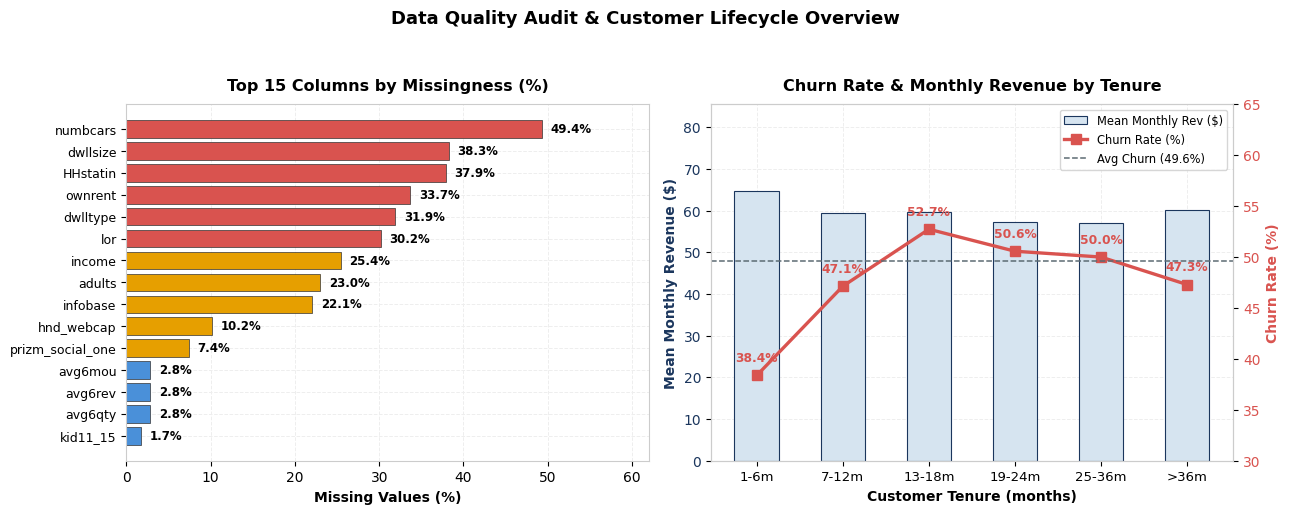

In [6]:
# Plot 1: Missingness & Tenure Lifecycle
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))
top_miss = miss_df.head(15).iloc[::-1]
y = np.arange(len(top_miss))
bar_colors = [CORAL if p > 30 else (AMBER if p > 5 else LIGHT_BLUE) for p in top_miss["missing_pct"]]
ax1.barh(y, top_miss["missing_pct"], color=bar_colors, edgecolor="#333333", linewidth=0.5)
for i, (_, row) in enumerate(top_miss.iterrows()):
    ax1.text(row["missing_pct"] + 1.0, i, f"{row['missing_pct']:.1f}%", va="center", fontsize=8.5, fontweight="bold")
ax1.set_yticks(y)
ax1.set_yticklabels(top_miss.index, fontsize=9)
ax1.set_xlabel("Missing Values (%)", fontsize=10, fontweight="bold")
ax1.set_xlim(0, 62)
ax1.set_title("Top 15 Columns by Missingness (%)", fontsize=11.5, fontweight="bold", pad=10)

x2 = np.arange(len(ten_res))
ax2.bar(x2, ten_res["rev_mean"], width=0.52, color="#D6E4F0", edgecolor=NAVY, linewidth=0.8, label="Mean Monthly Rev ($)")
ax2.set_ylabel("Mean Monthly Revenue ($)", color=NAVY, fontsize=10, fontweight="bold")
ax2.tick_params(axis="y", labelcolor=NAVY)
ax2.set_ylim(0, ten_res["rev_mean"].max() * 1.32)
ax2_r = ax2.twinx()
ax2_r.grid(False)
ax2_r.plot(x2, ten_res["churn_pct"], color=CORAL, marker="s", linewidth=2.4, markersize=7, label="Churn Rate (%)")
ax2_r.axhline(overall_churn, color=SLATE, linestyle="--", linewidth=1.1, label=f"Avg Churn ({overall_churn:.1f}%)")
ax2_r.set_ylabel("Churn Rate (%)", color=CORAL, fontsize=10, fontweight="bold")
ax2_r.tick_params(axis="y", labelcolor=CORAL)
ax2_r.set_ylim(30, 65)
for i, row in ten_res.iterrows():
    ax2_r.annotate(f"{row['churn_pct']:.1f}%", (i, row["churn_pct"]), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8.8, fontweight="bold", color=CORAL)
ax2.set_xticks(x2)
ax2.set_xticklabels(ten_res["months"], fontsize=9.5)
ax2.set_xlabel("Customer Tenure (months)", fontsize=10, fontweight="bold")
ax2.set_title("Churn Rate & Monthly Revenue by Tenure", fontsize=11.5, fontweight="bold", pad=10)
lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_r.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc="upper right", fontsize=8.3, frameon=True, facecolor="white")
fig.suptitle("Data Quality Audit & Customer Lifecycle Overview", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

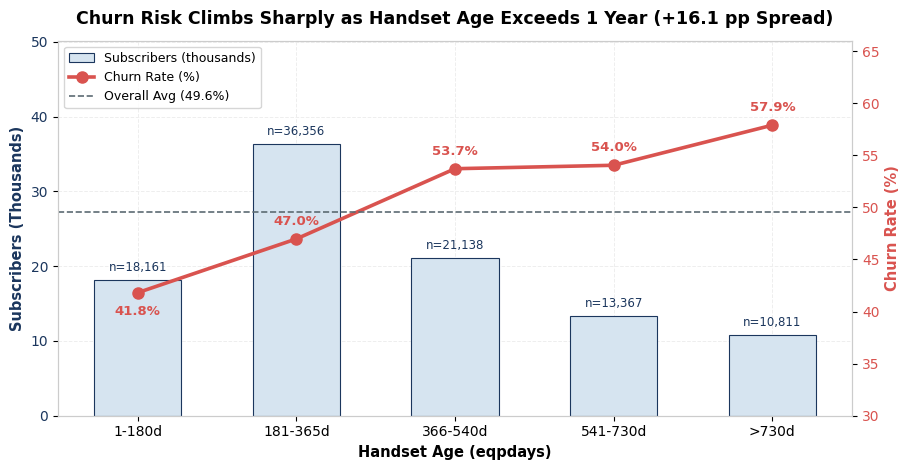

In [7]:
# Plot 2: Churn Risk by Handset Age (eqpdays)
sub_eqp = eqp_res[eqp_res["eqpdays"] != "<=0 (Anomaly)"].copy()
fig, ax1 = plt.subplots(figsize=(9.2, 4.8))
x = np.arange(len(sub_eqp))
ax1.bar(x, sub_eqp["n"] / 1000, width=0.55, color="#D6E4F0", edgecolor=NAVY, linewidth=0.8, label="Subscribers (thousands)")
ax1.set_ylabel("Subscribers (Thousands)", color=NAVY, fontsize=10.5, fontweight="bold")
ax1.tick_params(axis="y", labelcolor=NAVY)
ax1.set_ylim(0, sub_eqp["n"].max() / 1000 * 1.38)
ax2 = ax1.twinx()
ax2.grid(False)
ax2.plot(x, sub_eqp["churn_pct"], color=CORAL, marker="o", linewidth=2.6, markersize=8, label="Churn Rate (%)")
ax2.axhline(overall_churn, color=SLATE, linestyle="--", linewidth=1.2, label=f"Overall Avg ({overall_churn:.1f}%)")
ax2.set_ylabel("Churn Rate (%)", color=CORAL, fontsize=10.5, fontweight="bold")
ax2.tick_params(axis="y", labelcolor=CORAL)
ax2.set_ylim(30, 66)
for i, (_, row) in enumerate(sub_eqp.iterrows()):
    ax2.annotate(f"{row['churn_pct']:.1f}%", (i, row["churn_pct"]), textcoords="offset points", xytext=(0, -16 if i == 0 else 10), ha="center", fontsize=9.5, fontweight="bold", color=CORAL)
    ax1.text(i, row["n"] / 1000 + 0.8, f"n={int(row['n']):,}", ha="center", va="bottom", fontsize=8.5, color=NAVY)
ax1.set_xticks(x)
ax1.set_xticklabels(sub_eqp["eqpdays"], fontsize=10)
ax1.set_xlabel("Handset Age (eqpdays)", fontsize=10.5, fontweight="bold")
plt.title("Churn Risk Climbs Sharply as Handset Age Exceeds 1 Year (+16.1 pp Spread)", fontsize=12.5, fontweight="bold", pad=12)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", frameon=True, facecolor="white", fontsize=9)
plt.tight_layout()
plt.show()

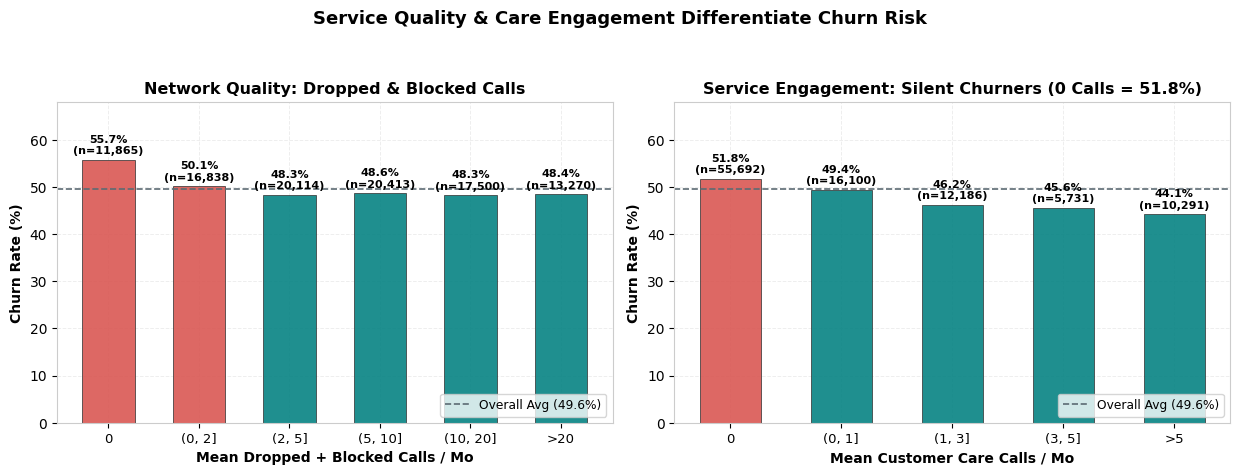

In [8]:
# Plot 3: Network Quality & Customer Care
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))
x1 = np.arange(len(db_res))
colors1 = [TEAL if v < overall_churn else CORAL for v in db_res["churn_pct"]]
ax1.bar(x1, db_res["churn_pct"], width=0.58, color=colors1, alpha=0.88, edgecolor="#333333", linewidth=0.6)
ax1.axhline(overall_churn, color=SLATE, linestyle="--", linewidth=1.2, label=f"Overall Avg ({overall_churn:.1f}%)")
for i, row in db_res.iterrows():
    ax1.text(i, row["churn_pct"] + 0.8, f"{row['churn_pct']:.1f}%\n(n={int(row['n']):,})", ha="center", va="bottom", fontsize=8.0, fontweight="bold")
ax1.set_xticks(x1)
ax1.set_xticklabels(db_res["drop_blk_Mean"], fontsize=9.5)
ax1.set_xlabel("Mean Dropped + Blocked Calls / Mo", fontsize=10, fontweight="bold")
ax1.set_ylabel("Churn Rate (%)", fontsize=10, fontweight="bold")
ax1.set_ylim(0, 68)
ax1.set_title("Network Quality: Dropped & Blocked Calls", fontsize=11.5, fontweight="bold")
ax1.legend(loc="lower right", fontsize=8.8)

x2 = np.arange(len(cc_res))
colors2 = [CORAL if v >= overall_churn else TEAL for v in cc_res["churn_pct"]]
ax2.bar(x2, cc_res["churn_pct"], width=0.55, color=colors2, alpha=0.88, edgecolor="#333333", linewidth=0.6)
ax2.axhline(overall_churn, color=SLATE, linestyle="--", linewidth=1.2, label=f"Overall Avg ({overall_churn:.1f}%)")
for i, row in cc_res.iterrows():
    ax2.text(i, row["churn_pct"] + 0.8, f"{row['churn_pct']:.1f}%\n(n={int(row['n']):,})", ha="center", va="bottom", fontsize=8.0, fontweight="bold")
ax2.set_xticks(x2)
ax2.set_xticklabels(cc_res["custcare_Mean"], fontsize=9.5)
ax2.set_xlabel("Mean Customer Care Calls / Mo", fontsize=10, fontweight="bold")
ax2.set_ylabel("Churn Rate (%)", fontsize=10, fontweight="bold")
ax2.set_ylim(0, 68)
ax2.set_title("Service Engagement: Silent Churners (0 Calls = 51.8%)", fontsize=11.5, fontweight="bold")
ax2.legend(loc="lower right", fontsize=8.8)
fig.suptitle("Service Quality & Care Engagement Differentiate Churn Risk", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

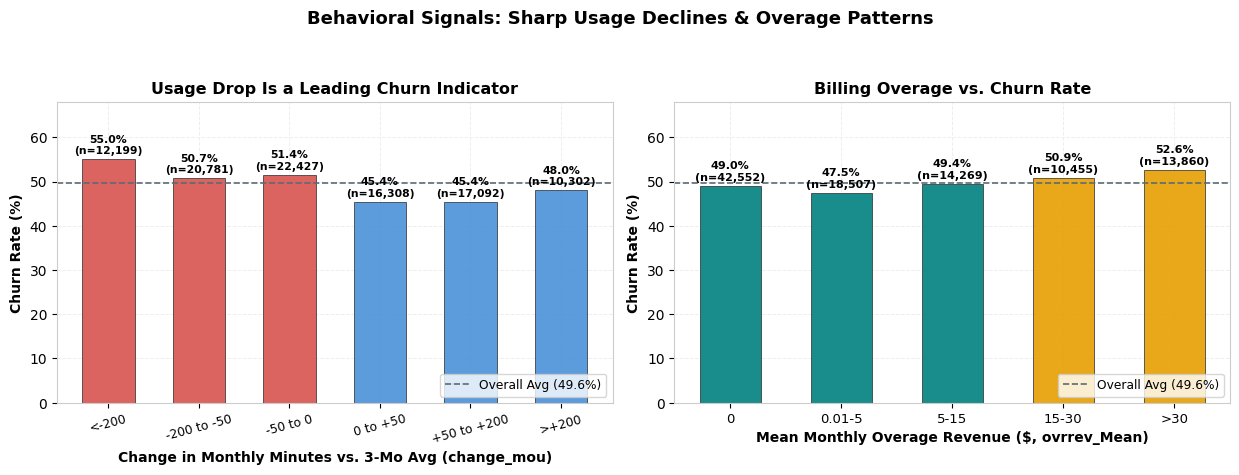

In [9]:
# Plot 4: Usage Decline & Overage Revenue
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))
x1 = np.arange(len(cmou_res))
colors1 = [CORAL if v > overall_churn else LIGHT_BLUE for v in cmou_res["churn_pct"]]
ax1.bar(x1, cmou_res["churn_pct"], width=0.58, color=colors1, alpha=0.9, edgecolor="#333333", linewidth=0.6)
ax1.axhline(overall_churn, color=SLATE, linestyle="--", linewidth=1.2, label=f"Overall Avg ({overall_churn:.1f}%)")
for i, row in cmou_res.iterrows():
    ax1.text(i, row["churn_pct"] + 0.8, f"{row['churn_pct']:.1f}%\n(n={int(row['n']):,})", ha="center", va="bottom", fontsize=7.8, fontweight="bold")
ax1.set_xticks(x1)
ax1.set_xticklabels(cmou_res["change_mou"], fontsize=8.8, rotation=15)
ax1.set_xlabel("Change in Monthly Minutes vs. 3-Mo Avg (change_mou)", fontsize=10, fontweight="bold")
ax1.set_ylabel("Churn Rate (%)", fontsize=10, fontweight="bold")
ax1.set_ylim(0, 68)
ax1.set_title("Usage Drop Is a Leading Churn Indicator", fontsize=11.5, fontweight="bold")
ax1.legend(loc="lower right", fontsize=8.8)

x2 = np.arange(len(ovr_res))
colors2 = [TEAL if v < overall_churn else AMBER for v in ovr_res["churn_pct"]]
ax2.bar(x2, ovr_res["churn_pct"], width=0.55, color=colors2, alpha=0.9, edgecolor="#333333", linewidth=0.6)
ax2.axhline(overall_churn, color=SLATE, linestyle="--", linewidth=1.2, label=f"Overall Avg ({overall_churn:.1f}%)")
for i, row in ovr_res.iterrows():
    ax2.text(i, row["churn_pct"] + 0.8, f"{row['churn_pct']:.1f}%\n(n={int(row['n']):,})", ha="center", va="bottom", fontsize=8.0, fontweight="bold")
ax2.set_xticks(x2)
ax2.set_xticklabels(["0", "0.01-5", "5-15", "15-30", ">30"], fontsize=9.5)
ax2.set_xlabel("Mean Monthly Overage Revenue ($, ovrrev_Mean)", fontsize=10, fontweight="bold")
ax2.set_ylabel("Churn Rate (%)", fontsize=10, fontweight="bold")
ax2.set_ylim(0, 68)
ax2.set_title("Billing Overage vs. Churn Rate", fontsize=11.5, fontweight="bold")
ax2.legend(loc="lower right", fontsize=8.8)
fig.suptitle("Behavioral Signals: Sharp Usage Declines & Overage Patterns", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

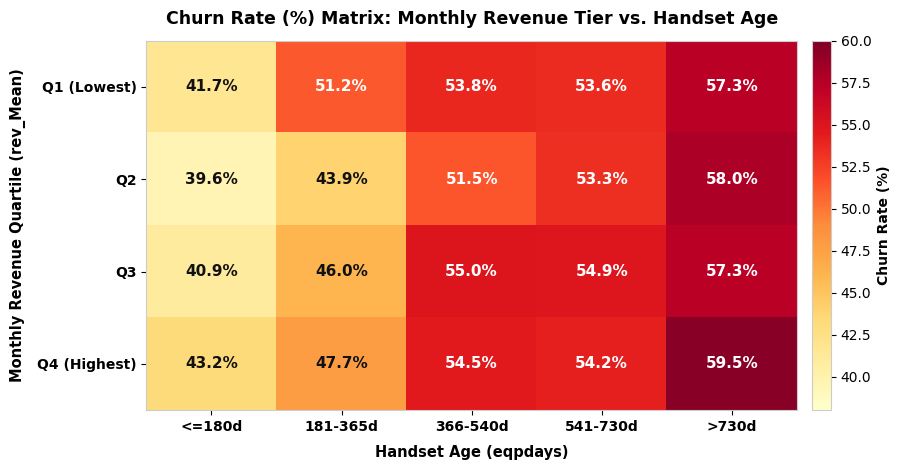

In [10]:
# Plot 5: Revenue Quartile x Handset Age Heatmap
fig, ax = plt.subplots(figsize=(9.5, 4.8))
data_ct = ct.values
im = ax.imshow(data_ct, cmap="YlOrRd", aspect="auto", vmin=38, vmax=60)
ax.set_xticks(np.arange(len(ct.columns)))
ax.set_xticklabels(ct.columns, fontsize=10, fontweight="bold")
ax.set_yticks(np.arange(len(ct.index)))
ax.set_yticklabels(ct.index, fontsize=10, fontweight="bold")
ax.set_xlabel("Handset Age (eqpdays)", fontsize=10.5, fontweight="bold", labelpad=8)
ax.set_ylabel("Monthly Revenue Quartile (rev_Mean)", fontsize=10.5, fontweight="bold", labelpad=8)
for i in range(data_ct.shape[0]):
    for j in range(data_ct.shape[1]):
        val = data_ct[i, j]
        txt_color = "white" if val > 51 else "#111111"
        ax.text(j, i, f"{val:.1f}%", ha="center", va="center", color=txt_color, fontsize=11, fontweight="bold")
cbar = plt.colorbar(im, ax=ax, pad=0.02)
cbar.set_label("Churn Rate (%)", fontsize=10, fontweight="bold")
ax.grid(False)
plt.title("Churn Rate (%) Matrix: Monthly Revenue Tier vs. Handset Age", fontsize=12.5, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## 4. Problem Definition & Leakage-Free Feature Engineering

### 4.1 Modeling Framing & Validation Protocol
* **Target (`churn`):** Binary indicator of subscriber churn occurring 31–60 days after the observation date (`49.56%` positive class).
* **Train/Test Split:** Stratified `80/20` split (`80,000` train / `20,000` held-out test, `random_state=42`).
* **Leak-Free Preprocessing:** All imputation (`SimpleImputer(strategy="median", add_indicator=True)` for numeric; `"MISSING"` + `OneHotEncoder(handle_unknown="ignore")` for categoricals) and `StandardScaler` (for Logistic Regression) are fit **strictly inside `sklearn` Pipelines** on training folds only.
* **Anomaly Cleaning & 13 Engineered Features:**
  * Clip `eqpdays < 0` (`133` rows) and `rev_Mean < 0` (`5` rows) to `0`, preserving `eqpdays_neg_flag` and `rev_neg_flag`.
  * Engineer 13 row-wise, zero-leakage intervenable & behavioral features: `overage_share`, `drop_blk_rate`, `comp_rate`, `rev_trend_ratio`, `mou_trend_ratio`, `eqp_per_month`, `care_per_mou`, `eqpdays_gt_365`, `has_custcare`, `active_line_ratio`, `mou_per_rev`, `roam_share`, `mrc_share`.

In [11]:
def prepare_features(df_raw):
    d = df_raw.copy()
    # Anomaly flags & clipping
    d["eqpdays_neg_flag"] = (d["eqpdays"] < 0).astype(int)
    d["eqpdays"] = d["eqpdays"].clip(lower=0)
    d["rev_neg_flag"] = (d["rev_Mean"] < 0).astype(int)
    d["rev_Mean"] = d["rev_Mean"].clip(lower=0)

    # Safe denominators
    rev_denom = d["rev_Mean"].clip(lower=1.0)
    att_denom = d["attempt_Mean"].clip(lower=1.0)
    mou_denom = d["mou_Mean"].clip(lower=1.0)
    avg6rev_denom = d["avg6rev"].clip(lower=1.0)
    avg6mou_denom = d["avg6mou"].clip(lower=1.0)
    months_days = (d["months"] * 30.0).clip(lower=1.0)
    uniq_denom = d["uniqsubs"].clip(lower=1.0)

    # 13 engineered intervenable & behavioral features
    d["overage_share"] = d["ovrrev_Mean"] / rev_denom
    d["drop_blk_rate"] = d["drop_blk_Mean"] / att_denom
    d["comp_rate"] = d["complete_Mean"] / att_denom
    d["rev_trend_ratio"] = d["avg3rev"] / avg6rev_denom
    d["mou_trend_ratio"] = d["avg3mou"] / avg6mou_denom
    d["eqp_per_month"] = d["eqpdays"] / months_days
    d["care_per_mou"] = d["custcare_Mean"] / mou_denom
    d["eqpdays_gt_365"] = np.where(d["eqpdays"].isna(), np.nan, (d["eqpdays"] > 365).astype(float))
    d["has_custcare"] = np.where(d["custcare_Mean"].isna(), np.nan, (d["custcare_Mean"] > 0).astype(float))
    d["active_line_ratio"] = d["actvsubs"] / uniq_denom
    d["mou_per_rev"] = d["mou_Mean"] / rev_denom
    d["roam_share"] = d["roam_Mean"] / rev_denom
    d["mrc_share"] = d["totmrc_Mean"] / rev_denom
    return d

df_feat = prepare_features(df)
drop_cols = ["Customer_ID", "churn"]
feature_cols = [c for c in df_feat.columns if c not in drop_cols]
cat_cols = df_feat[feature_cols].select_dtypes(include=["object", "category", "string"]).columns.tolist()
num_cols = [c for c in feature_cols if c not in cat_cols]

X = df_feat[feature_cols]
y = df_feat["churn"].astype(int)

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df_feat.index, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Prepared dataset: {df_feat.shape} -> {len(feature_cols)} features ({len(num_cols)} numeric, {len(cat_cols)} categorical)")
print(f"Train shape: {X_train.shape} (churn={y_train.mean():.4f}) | Test shape: {X_test.shape} (churn={y_test.mean():.4f})")

Prepared dataset: (100000, 115) -> 113 features (92 numeric, 21 categorical)
Train shape: (80000, 113) (churn=0.4956) | Test shape: (20000, 113) (churn=0.4956)


## 5. Multi-Model Experiments & Evaluation

### 5.1 5-Fold Stratified CV & Held-Out Test Comparison
We benchmark four model families—**Logistic Regression**, **Random Forest**, **XGBoost**, and **LightGBM**—under identical leak-free preprocessing pipelines (`adjqty`, `adjmou`, `adjrev` dropped for Logistic Regression to prevent collinearity instability).

In [12]:
def build_preprocessor(n_cols, c_cols, scale_numeric=False):
    num_steps = [("imputer", SimpleImputer(strategy="median", add_indicator=True))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))
    num_pipe = Pipeline(num_steps)
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer(
        transformers=[("num", num_pipe, n_cols), ("cat", cat_pipe, c_cols)],
        remainder="drop",
        verbose_feature_names_out=False,
    )

def compute_metrics(y_true, y_prob, threshold=0.50):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "recall": recall_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
    }

lr_num_cols = [c for c in num_cols if c not in {"adjqty", "adjmou", "adjrev"}]
model_specs = {
    "Logistic Regression": {
        "num_cols": lr_num_cols,
        "scale": True,
        "estimator": lambda: LogisticRegression(C=1.0, max_iter=1000, solver="lbfgs", random_state=RANDOM_STATE),
    },
    "Random Forest": {
        "num_cols": num_cols,
        "scale": False,
        "estimator": lambda: RandomForestClassifier(n_estimators=300, max_depth=16, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE),
    },
    "XGBoost": {
        "num_cols": num_cols,
        "scale": False,
        "estimator": lambda: XGBClassifier(
            n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
            colsample_bytree=0.8, reg_lambda=2.0, eval_metric="logloss",
            tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE
        ),
    },
    "LightGBM": {
        "num_cols": num_cols,
        "scale": False,
        "estimator": lambda: LGBMClassifier(
            n_estimators=400, max_depth=6, num_leaves=31, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0, n_jobs=-1,
            random_state=RANDOM_STATE, verbose=-1
        ),
    },
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, oof_preds, test_preds, fitted_pipelines = [], {}, {}, {}

for name, spec in model_specs.items():
    t0 = time.time()
    fold_metrics = []
    oof_prob = np.zeros(len(X_train), dtype=float)
    for tr_idx, val_idx in cv.split(X_train, y_train):
        pipe = Pipeline([
            ("prep", build_preprocessor(spec["num_cols"], cat_cols, scale_numeric=spec["scale"])),
            ("clf", spec["estimator"]()),
        ])
        pipe.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        val_prob = pipe.predict_proba(X_train.iloc[val_idx])[:, 1]
        oof_prob[val_idx] = val_prob
        fold_metrics.append(compute_metrics(y_train.iloc[val_idx], val_prob, threshold=0.50))

    full_pipe = Pipeline([
        ("prep", build_preprocessor(spec["num_cols"], cat_cols, scale_numeric=spec["scale"])),
        ("clf", spec["estimator"]()),
    ])
    full_pipe.fit(X_train, y_train)
    test_prob = full_pipe.predict_proba(X_test)[:, 1]
    test_m = compute_metrics(y_test, test_prob, threshold=0.50)

    oof_preds[name] = oof_prob
    test_preds[name] = test_prob
    fitted_pipelines[name] = full_pipe

    fold_df = pd.DataFrame(fold_metrics)
    row = {"model": name, "elapsed_s": round(time.time() - t0, 1)}
    for k in ["roc_auc", "pr_auc", "recall", "precision", "f1", "accuracy"]:
        row[f"cv_{k}_mean"] = fold_df[k].mean()
        row[f"cv_{k}_std"] = fold_df[k].std()
        row[f"test_{k}"] = test_m[k]
    results.append(row)
    print(f"{name:20s} | CV ROC-AUC: {row['cv_roc_auc_mean']:.4f} +/- {row['cv_roc_auc_std']:.4f} | Test ROC-AUC: {row['test_roc_auc']:.4f} | Test PR-AUC: {row['test_pr_auc']:.4f} ({row['elapsed_s']}s)")

results_df = pd.DataFrame(results).sort_values("test_roc_auc", ascending=False).reset_index(drop=True)
display(results_df[["model", "cv_roc_auc_mean", "cv_roc_auc_std", "test_roc_auc", "cv_pr_auc_mean", "test_pr_auc", "test_recall", "test_precision", "test_f1", "test_accuracy"]].round(4))

Logistic Regression  | CV ROC-AUC: 0.6380 +/- 0.0023 | Test ROC-AUC: 0.6409 | Test PR-AUC: 0.6226 (21.2s)


Random Forest        | CV ROC-AUC: 0.6772 +/- 0.0054 | Test ROC-AUC: 0.6779 | Test PR-AUC: 0.6598 (29.7s)


XGBoost              | CV ROC-AUC: 0.6977 +/- 0.0042 | Test ROC-AUC: 0.6981 | Test PR-AUC: 0.6864 (21.9s)


LightGBM             | CV ROC-AUC: 0.6978 +/- 0.0055 | Test ROC-AUC: 0.6974 | Test PR-AUC: 0.6858 (15.5s)


,model,cv_roc_auc_mean,cv_roc_auc_std,test_roc_auc,cv_pr_auc_mean,test_pr_auc,test_recall,test_precision,test_f1,test_accuracy
0,XGBoost,0.6977,0.0042,0.6981,0.6832,0.6864,0.6533,0.6372,0.6451,0.6438
1,LightGBM,0.6978,0.0055,0.6974,0.6831,0.6858,0.6448,0.6321,0.6384,0.6380
2,Random Forest,0.6772,0.0054,0.6779,0.6586,0.6598,0.6439,0.6159,0.6296,0.6245
3,Logistic Regression,0.6380,0.0023,0.6409,0.6170,0.6226,0.5919,0.6003,0.5961,0.6024


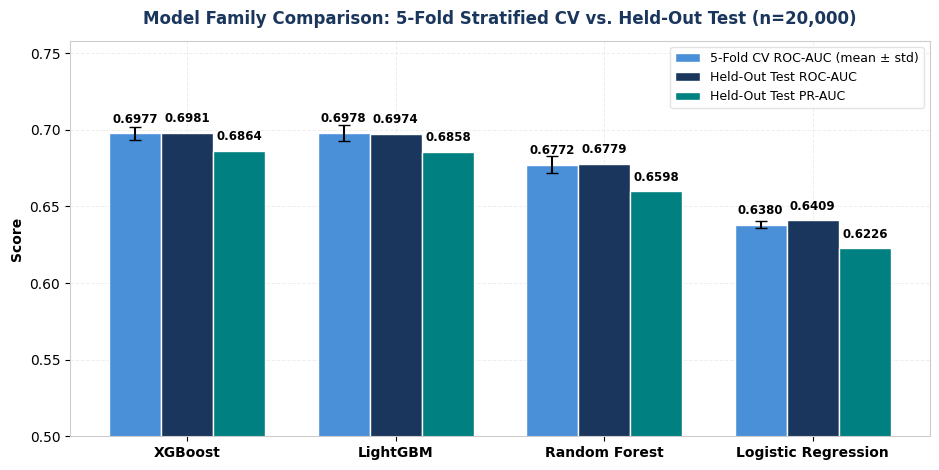

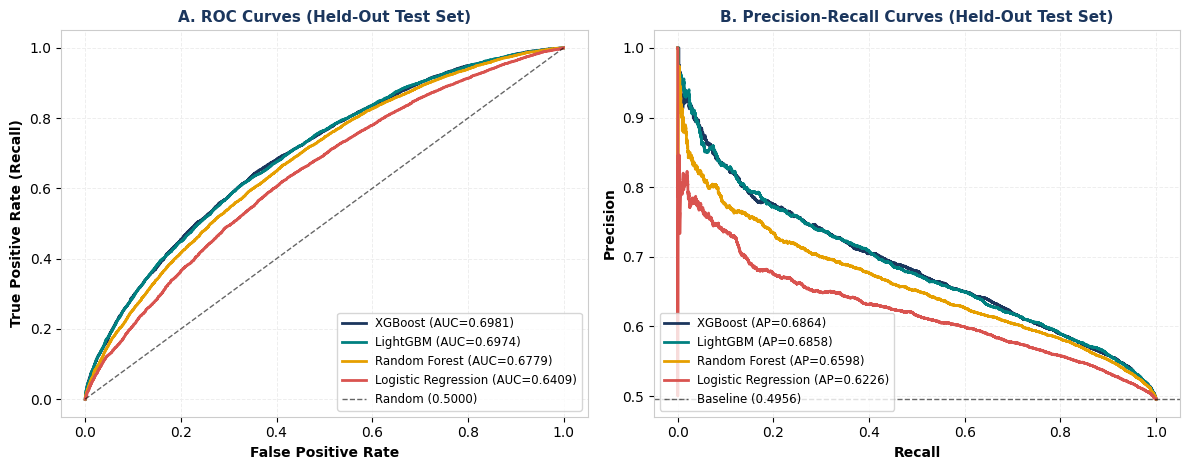

In [13]:
# Plot 6: Model Comparison Bar Chart
fig, ax = plt.subplots(figsize=(9.5, 4.8))
models = results_df["model"].tolist()
x = np.arange(len(models))
w = 0.25
b1 = ax.bar(x - w, results_df["cv_roc_auc_mean"], width=w, yerr=results_df["cv_roc_auc_std"], capsize=4, color=LIGHT_BLUE, label="5-Fold CV ROC-AUC (mean ± std)", edgecolor="white")
b2 = ax.bar(x, results_df["test_roc_auc"], width=w, color=NAVY, label="Held-Out Test ROC-AUC", edgecolor="white")
b3 = ax.bar(x + w, results_df["test_pr_auc"], width=w, color=TEAL, label="Held-Out Test PR-AUC", edgecolor="white")
for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.005, f"{h:.4f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=10, fontweight="bold")
ax.set_ylim(0.50, max(results_df["test_roc_auc"].max(), results_df["test_pr_auc"].max()) + 0.06)
ax.set_ylabel("Score", fontsize=10, fontweight="bold")
ax.set_title("Model Family Comparison: 5-Fold Stratified CV vs. Held-Out Test (n=20,000)", fontsize=12, fontweight="bold", pad=12, color=NAVY)
ax.legend(frameon=True, facecolor="white", edgecolor="#DDDDDD", fontsize=9, loc="upper right")
plt.tight_layout()
plt.show()

# Plot 7: ROC & PR Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.0, 4.8))
palette = {"LightGBM": TEAL, "XGBoost": NAVY, "Random Forest": AMBER, "Logistic Regression": CORAL}
for _, row in results_df.iterrows():
    m = row["model"]
    prob = test_preds[m]
    c = palette.get(m, SLATE)
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax1.plot(fpr, tpr, lw=2.0, color=c, label=f"{m} (AUC={row['test_roc_auc']:.4f})")
    prec, rec, _ = precision_recall_curve(y_test, prob)
    ax2.plot(rec, prec, lw=2.0, color=c, label=f"{m} (AP={row['test_pr_auc']:.4f})")
ax1.plot([0, 1], [0, 1], "k--", lw=1.0, alpha=0.6, label="Random (0.5000)")
ax1.set_xlabel("False Positive Rate", fontsize=10, fontweight="bold")
ax1.set_ylabel("True Positive Rate (Recall)", fontsize=10, fontweight="bold")
ax1.set_title("A. ROC Curves (Held-Out Test Set)", fontsize=11, fontweight="bold", color=NAVY)
ax1.legend(loc="lower right", fontsize=8.5, frameon=True)

baseline = y_test.mean()
ax2.axhline(baseline, color="k", linestyle="--", lw=1.0, alpha=0.6, label=f"Baseline ({baseline:.4f})")
ax2.set_xlabel("Recall", fontsize=10, fontweight="bold")
ax2.set_ylabel("Precision", fontsize=10, fontweight="bold")
ax2.set_title("B. Precision-Recall Curves (Held-Out Test Set)", fontsize=11, fontweight="bold", color=NAVY)
ax2.legend(loc="lower left", fontsize=8.5, frameon=True)
plt.tight_layout()
plt.show()

### 5.2 Threshold Tuning, Risk Stratification & Top Intervenable Drivers (XGBoost)
**XGBoost** wins on held-out Test ROC-AUC (`0.6981`), PR-AUC (`0.6864`), F1 (`0.6451`), and Accuracy (`0.6438`), outperforming Logistic Regression by **`+5.7 pp` ROC-AUC** (`0.6981` vs. `0.6409`) with virtually zero CV-to-Test generalization gap (`0.6977 -> 0.6981`).

* **Threshold Tuning (`0.40`):** Lowering the decision threshold from `0.50` to `0.40` increases Test Recall from `0.6533` to **`0.8395`** (`F2 = 0.7695`), capturing nearly `84%` of all churners for low-cost digital outreach.
* **Risk Quintile & Decile Lift:** Top Quintile `Q5` achieves **`74.00%` actual churn (`1.49x` lift)** and `$162,920/mo` at risk, while Top Decile `D10` reaches **`78.50%` (`1.58x` lift)** vs. `19.40%` in `D1` (**`4.05x` top-to-bottom separation**).
* **Intervenable Drivers:** **10 of the top 15** XGBoost features are directly intervenable, led by `eqpdays_gt_365` (`4.63%`), `eqpdays` (`2.59%`), `hnd_price` (`1.21%`), `refurb_new` (`1.13%`/`1.07%`), and `asl_flag` (`0.98%`/`0.95%`).

In [14]:
winner_name = results_df.loc[0, "model"]
winner_pipe = fitted_pipelines[winner_name]
winner_num_cols = model_specs[winner_name]["num_cols"]
winner_oof = oof_preds[winner_name]
winner_test_prob = test_preds[winner_name]
print(f"Winning Model: {winner_name}")

# Threshold analysis
thresh_rows = []
for t in [0.35, 0.40, 0.45, 0.50, 0.55]:
    m_cv = compute_metrics(y_train, winner_oof, threshold=t)
    m_te = compute_metrics(y_test, winner_test_prob, threshold=t)
    f2_cv = (5 * m_cv["precision"] * m_cv["recall"]) / max(4 * m_cv["precision"] + m_cv["recall"], 1e-9)
    f2_te = (5 * m_te["precision"] * m_te["recall"]) / max(4 * m_te["precision"] + m_te["recall"], 1e-9)
    thresh_rows.append({
        "threshold": t,
        "flagged_pct_test": round((winner_test_prob >= t).mean() * 100, 2),
        "cv_recall": round(m_cv["recall"], 4), "cv_precision": round(m_cv["precision"], 4),
        "cv_f1": round(m_cv["f1"], 4), "cv_f2": round(f2_cv, 4),
        "test_recall": round(m_te["recall"], 4), "test_precision": round(m_te["precision"], 4),
        "test_f1": round(m_te["f1"], 4), "test_f2": round(f2_te, 4),
        "test_accuracy": round(m_te["accuracy"], 4),
    })
print("\n--- Threshold & Asymmetric Cost Trade-Off ---")
display(pd.DataFrame(thresh_rows))

# Risk Quintile & Decile tables
test_out = df_feat.loc[idx_test, [
    "Customer_ID", "rev_Mean", "eqpdays", "ovrrev_Mean", "custcare_Mean",
    "drop_blk_Mean", "change_mou", "months", "hnd_price", "asl_flag", "refurb_new"
]].copy()
test_out["churn"] = y_test.values
test_out["pred_prob"] = winner_test_prob
test_out["risk_quintile"] = pd.qcut(test_out["pred_prob"], q=5, labels=["Q1 (Lowest)", "Q2", "Q3", "Q4", "Q5 (Highest)"])
test_out["risk_decile"] = pd.qcut(test_out["pred_prob"], q=10, labels=[f"D{i}" for i in range(1, 11)])

def agg_risk(df_in, group_col):
    base = test_out["churn"].mean()
    g = df_in.groupby(group_col, observed=False).agg(
        n=("Customer_ID", "count"),
        churners=("churn", "sum"),
        churn_rate=("churn", "mean"),
        churned_rev_mo=("rev_Mean", lambda s: s[df_in.loc[s.index, "churn"] == 1].sum()),
        mean_rev=("rev_Mean", "mean"),
        mean_eqpdays=("eqpdays", "mean"),
    ).reset_index()
    g["lift_vs_base"] = g["churn_rate"] / base
    g["churn_pct"] = g["churn_rate"] * 100
    return g

quintile_tbl = agg_risk(test_out, "risk_quintile")
decile_tbl = agg_risk(test_out, "risk_decile")
hv_test = test_out[test_out["rev_Mean"] >= 70.76].copy()
hv_quintile_tbl = agg_risk(hv_test, "risk_quintile")

print("\n--- Test Risk Quintile Lift (All Test, n=20,000) ---")
display(quintile_tbl[["risk_quintile", "n", "churners", "churn_pct", "lift_vs_base", "churned_rev_mo", "mean_rev", "mean_eqpdays"]].round(2))
print(f"Top Decile (D10): {decile_tbl.loc[9, 'churn_pct']:.2f}% churn ({decile_tbl.loc[9, 'lift_vs_base']:.2f}x lift) vs D1: {decile_tbl.loc[0, 'churn_pct']:.2f}%")
print("\n--- High-Value Segment (rev_Mean >= $70.76, n=5,027 in Test) by Risk Quintile ---")
display(hv_quintile_tbl[["risk_quintile", "n", "churners", "churn_pct", "lift_vs_base", "churned_rev_mo", "mean_rev", "mean_eqpdays"]].round(2))

Winning Model: XGBoost



--- Threshold & Asymmetric Cost Trade-Off ---


,threshold,flagged_pct_test,cv_recall,cv_precision,cv_f1,cv_f2,test_recall,test_precision,test_f1,test_f2,test_accuracy
0,0.35,80.18,0.8999,0.5579,0.6888,0.8016,0.9025,0.5579,0.6895,0.8033,0.5972
1,0.40,72.11,0.8398,0.5792,0.6855,0.7705,0.8395,0.5769,0.6839,0.7695,0.6153
2,0.45,62.15,0.7577,0.6052,0.6729,0.7214,0.7550,0.6021,0.6699,0.7185,0.6313
3,0.50,50.82,0.6481,0.6359,0.6419,0.6456,0.6533,0.6372,0.6451,0.6500,0.6438
4,0.55,38.66,0.5195,0.6683,0.5846,0.5437,0.5221,0.6693,0.5866,0.5461,0.6353



--- Test Risk Quintile Lift (All Test, n=20,000) ---


,risk_quintile,n,churners,churn_pct,lift_vs_base,churned_rev_mo,mean_rev,mean_eqpdays
0,Q1 (Lowest),4000,980,24.50,0.49,62819.57,59.99,227.43
1,Q2,4000,1638,40.95,0.83,100427.02,61.21,360.29
2,Q3,4000,1974,49.35,1.00,108767.51,56.26,432.96
3,Q4,4000,2360,59.00,1.19,135453.59,58.99,467.25
4,Q5 (Highest),4000,2960,74.00,1.49,162919.61,56.17,475.19


Top Decile (D10): 78.50% churn (1.58x lift) vs D1: 19.40%

--- High-Value Segment (rev_Mean >= $70.76, n=5,027 in Test) by Risk Quintile ---


,risk_quintile,n,churners,churn_pct,lift_vs_base,churned_rev_mo,mean_rev,mean_eqpdays
0,Q1 (Lowest),1071,320,29.88,0.60,34651.59,108.09,188.77
1,Q2,1134,467,41.18,0.83,53715.88,114.18,269.17
2,Q3,920,431,46.85,0.95,47045.14,111.31,315.06
3,Q4,986,557,56.49,1.14,64604.10,118.13,358.60
4,Q5 (Highest),916,646,70.52,1.42,74947.22,114.79,387.23


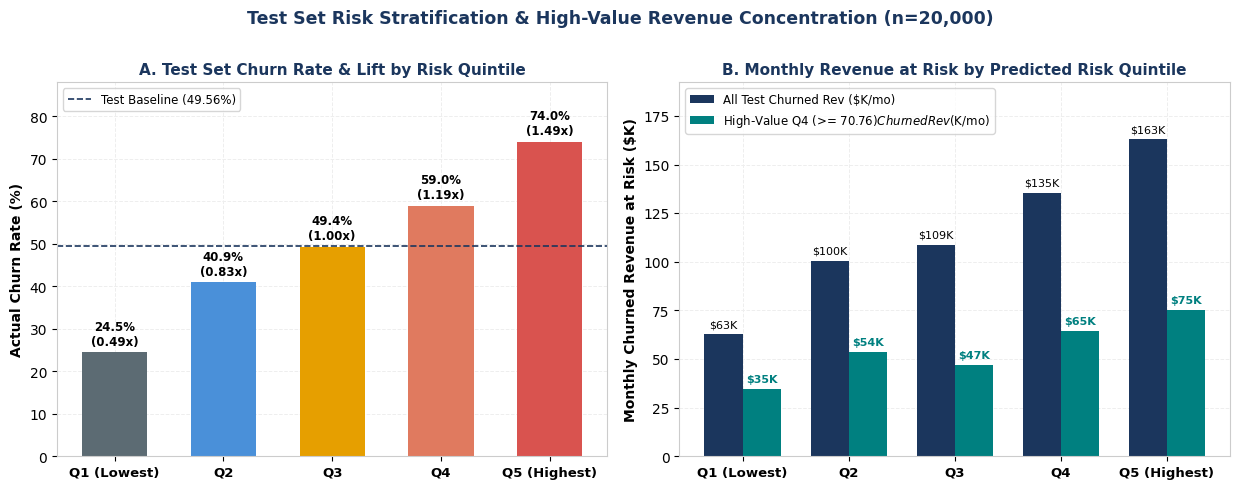

In [15]:
# Plot 8: Risk Quintile Lift & Revenue Concentration
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))
q_labels = quintile_tbl["risk_quintile"].astype(str).tolist()
x = np.arange(len(q_labels))
bars = ax1.bar(x, quintile_tbl["churn_pct"], color=[SLATE, LIGHT_BLUE, AMBER, "#E07A5F", CORAL], width=0.6)
ax1.axhline(test_out["churn"].mean() * 100, color=NAVY, linestyle="--", linewidth=1.2, label="Test Baseline (49.56%)")
for i, bar in enumerate(bars):
    h = bar.get_height()
    lift = quintile_tbl.loc[i, "lift_vs_base"]
    ax1.text(bar.get_x() + bar.get_width() / 2, h + 1.0, f"{h:.1f}%\n({lift:.2f}x)", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(q_labels, fontsize=9.5, fontweight="bold")
ax1.set_ylim(0, 88)
ax1.set_ylabel("Actual Churn Rate (%)", fontsize=10, fontweight="bold")
ax1.set_title("A. Test Set Churn Rate & Lift by Risk Quintile", fontsize=11, fontweight="bold", color=NAVY)
ax1.legend(loc="upper left", fontsize=8.5, frameon=True)

rev_all_k = quintile_tbl["churned_rev_mo"] / 1000.0
rev_hv_k = hv_quintile_tbl["churned_rev_mo"] / 1000.0
w = 0.36
b_all = ax2.bar(x - w / 2, rev_all_k, width=w, color=NAVY, label="All Test Churned Rev ($K/mo)")
b_hv = ax2.bar(x + w / 2, rev_hv_k, width=w, color=TEAL, label="High-Value Q4 (>= $70.76) Churned Rev ($K/mo)")
for bar in b_all:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 2.5, f"${h:.0f}K", ha="center", va="bottom", fontsize=8)
for bar in b_hv:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 2.5, f"${h:.0f}K", ha="center", va="bottom", fontsize=8, color=TEAL, fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(q_labels, fontsize=9.5, fontweight="bold")
ax2.set_ylim(0, rev_all_k.max() * 1.18)
ax2.set_ylabel("Monthly Churned Revenue at Risk ($K)", fontsize=10, fontweight="bold")
ax2.set_title("B. Monthly Revenue at Risk by Predicted Risk Quintile", fontsize=11, fontweight="bold", color=NAVY)
ax2.legend(loc="upper left", fontsize=8.5, frameon=True)
plt.suptitle("Test Set Risk Stratification & High-Value Revenue Concentration (n=20,000)", fontsize=12.5, fontweight="bold", color=NAVY, y=1.01)
plt.tight_layout()
plt.show()

,feature,importance_pct,category
0,eqpdays_gt_365,4.63,Intervenable
1,eqpdays,2.59,Intervenable
2,months,1.57,Structural
3,change_rev_is_missing,1.40,Intervenable
4,hnd_webcap_WCMB,1.30,Structural
5,hnd_price,1.21,Intervenable
6,income_is_missing,1.16,Structural
7,change_mou_is_missing,1.14,Intervenable
8,refurb_new_R,1.13,Intervenable
9,refurb_new_N,1.07,Intervenable


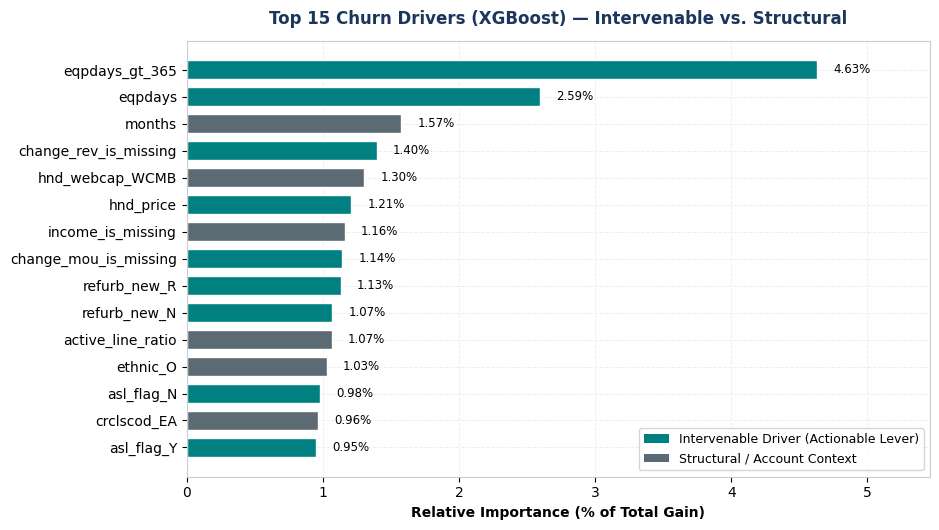

In [16]:
# Feature Importance (Top 15 XGBoost Drivers)
INTERVENVABLE_FEATURES = {
    "eqpdays", "eqp_per_month", "eqpdays_gt_365", "eqpdays_neg_flag",
    "hnd_price", "refurb_new", "dualband", "phones", "models",
    "overage_share", "ovrrev_Mean", "ovrmou_Mean", "vceovr_Mean", "datovr_Mean",
    "drop_blk_Mean", "drop_blk_rate", "comp_rate", "drop_vce_Mean", "blck_vce_Mean",
    "custcare_Mean", "care_per_mou", "has_custcare", "cc_mou_Mean", "ccrndmou_Mean",
    "change_mou", "change_rev", "mou_trend_ratio", "rev_trend_ratio",
    "asl_flag", "roam_share", "mrc_share", "mou_per_rev",
}

prep = winner_pipe.named_steps["prep"]
clf = winner_pipe.named_steps["clf"]
num_imp = prep.named_transformers_["num"].named_steps["imputer"]
feat_names = list(winner_num_cols)
if hasattr(num_imp, "indicator_") and num_imp.indicator_ is not None:
    feat_names.extend([f"{winner_num_cols[i]}_is_missing" for i in num_imp.indicator_.features_])
feat_names.extend(prep.named_transformers_["cat"].named_steps["ohe"].get_feature_names_out(cat_cols).tolist())

imp_df = pd.DataFrame({"feature": feat_names, "importance": clf.feature_importances_})
imp_df["importance_pct"] = imp_df["importance"] / imp_df["importance"].sum() * 100

def is_intervenable(f):
    base = f.replace("_is_missing", "")
    return (base in INTERVENVABLE_FEATURES) or any(base.startswith(p + "_") for p in INTERVENVABLE_FEATURES)

imp_df["category"] = np.where(imp_df["feature"].apply(is_intervenable), "Intervenable", "Structural")
imp_df = imp_df.sort_values("importance", ascending=False).reset_index(drop=True)
display(imp_df.head(15)[["feature", "importance_pct", "category"]].round(2))

# Plot 9: Feature Importance
top15 = imp_df.head(15).iloc[::-1].copy()
fig, ax = plt.subplots(figsize=(9.5, 5.4))
colors = [TEAL if c == "Intervenable" else SLATE for c in top15["category"]]
bars = ax.barh(top15["feature"], top15["importance_pct"], color=colors, edgecolor="white", height=0.7)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.12, bar.get_y() + bar.get_height() / 2, f"{w:.2f}%", va="center", ha="left", fontsize=8.5)
ax.set_xlim(0, top15["importance_pct"].max() * 1.18)
ax.set_xlabel("Relative Importance (% of Total Gain)", fontsize=10, fontweight="bold")
ax.set_title(f"Top 15 Churn Drivers ({winner_name}) — Intervenable vs. Structural", fontsize=12, fontweight="bold", pad=12, color=NAVY)
ax.legend(handles=[Patch(facecolor=TEAL, label="Intervenable Driver (Actionable Lever)"), Patch(facecolor=SLATE, label="Structural / Account Context")], loc="lower right", frameon=True, fontsize=9)
plt.tight_layout()
plt.show()

## 6. Quantified Business Proposal & 90-Day A/B Pilot

### 6.1 Two-Tier Retention Architecture (Scaled 5x to 100,000-Subscriber Base)
Rather than spending `$2.50M` on blanket retention (`$25/user` across all `100,000` subscribers, yielding only `37.4%` 6-month ROI and wasting `$1.26M` on non-churners), we propose a **Two-Tier Value-Matched Retention Program** targeting **`19,340` subscribers (`19.34%` of base, `68.56%` actual churn rate)**:

| Tier | Segment Rule | 100k Base N | Unit Cost | Intervention Playbook |
|---|---|---:|---:|---|
| **Tier 1A** | `rev_Mean >= $70.76` (Q4 HV) & `XGBoost Q4/Q5` & `eqpdays > 365` | `4,175` | `$45.00` | Proactive EIP/handset upgrade trade-in credit (`$35`) + priority concierge care (`$10`) |
| **Tier 1B** | `rev_Mean >= $70.76` (Q4 HV) & `XGBoost Q4/Q5` & `eqpdays <= 365` | `5,335` | `$25.00` | Plan-rightsizing / overage relief credit + ASL enrollment (`$15`) + proactive care (`$10`) |
| **Tier 2** | `rev_Mean < $70.76` & `XGBoost Q5` & (`eqpdays > 365` OR `ovrrev > $30` OR `ovr_ratio > 50%` OR silent usage drop) | `9,830` | `$15.00` | Automated SMS/app overage-cap or refurb-to-new swap voucher |
| **Total (T1+T2)** | Union of Tier 1A, 1B, and 2 | **`19,340`** | **`$24.23`** *(avg)* | **Total Program Spend: `$468,700`** (`81.3%` lower than blanket) |

In [17]:
SCALE_FACTOR = 5
HV_THRESHOLD = 70.76
BASE_WIN_BACK = 0.20
CAC_CONSERVATIVE = 250.0

biz_df = test_out.copy()
rev_median = biz_df["rev_Mean"].median()
biz_df["rev_clean"] = biz_df["rev_Mean"].fillna(rev_median).clip(lower=0.0)
biz_df["ovr_clean"] = biz_df["ovrrev_Mean"].fillna(0.0).clip(lower=0.0)
biz_df["ovr_ratio"] = biz_df["ovr_clean"] / biz_df["rev_clean"].clip(lower=1.0)

biz_df["is_hv"] = biz_df["rev_Mean"] >= HV_THRESHOLD
biz_df["is_q5"] = biz_df["risk_quintile"] == "Q5 (Highest)"
biz_df["is_q4_q5"] = biz_df["risk_quintile"].isin(["Q4", "Q5 (Highest)"])
biz_df["is_aging_handset"] = biz_df["eqpdays"] > 365
biz_df["is_ovr_shock"] = (biz_df["ovr_clean"] > 30.0) | (biz_df["ovr_ratio"] > 0.50)
biz_df["is_silent_drop"] = (biz_df["custcare_Mean"] == 0) & (biz_df["change_mou"] < -200)
biz_df["is_intervenable_mass"] = biz_df["is_aging_handset"] | biz_df["is_ovr_shock"] | biz_df["is_silent_drop"]

tier1a_mask = biz_df["is_hv"] & biz_df["is_q4_q5"] & biz_df["is_aging_handset"]
tier1b_mask = biz_df["is_hv"] & biz_df["is_q4_q5"] & (~biz_df["is_aging_handset"])
tier1_mask = tier1a_mask | tier1b_mask
tier2_mask = (~biz_df["is_hv"]) & biz_df["is_q5"] & biz_df["is_intervenable_mass"]
recommended_mask = tier1_mask | tier2_mask

tiered_cost = pd.Series(0.0, index=biz_df.index)
tiered_cost[tier1a_mask] = 45.0
tiered_cost[tier1b_mask] = 25.0
tiered_cost[tier2_mask] = 15.0

def evaluate_strategy(df_in, name, mask, unit_cost, win_back=BASE_WIN_BACK):
    sub = df_in[mask]
    n_test = len(sub)
    n_100k = n_test * SCALE_FACTOR
    churners_100k = int(sub["churn"].sum()) * SCALE_FACTOR
    churned_rev_mo_100k = sub.loc[sub["churn"] == 1, "rev_clean"].sum() * SCALE_FACTOR
    total_cost_100k = (unit_cost.loc[mask].sum() if isinstance(unit_cost, pd.Series) else n_test * float(unit_cost)) * SCALE_FACTOR
    retained_100k = churners_100k * win_back
    gross_6m = churned_rev_mo_100k * 6.0 * win_back
    gross_12m = churned_rev_mo_100k * 12.0 * win_back
    net_6m = gross_6m - total_cost_100k
    net_12m = gross_12m - total_cost_100k
    return {
        "Strategy": name,
        "Base_100k_N": n_100k,
        "Pct_Base": round(n_test / len(df_in) * 100.0, 2),
        "Seg_Churn_Pct": round(sub["churn"].mean() * 100.0, 2),
        "Actual_Churners_100k": churners_100k,
        "Retained_100k": int(round(retained_100k)),
        "Total_Cost_100k": round(total_cost_100k, 0),
        "Gross_Rev_6m": round(gross_6m, 0),
        "Net_Impact_6m": round(net_6m, 0),
        "ROI_6m_Pct": round(net_6m / total_cost_100k * 100.0, 1),
        "Gross_Rev_12m": round(gross_12m, 0),
        "Net_Impact_12m": round(net_12m, 0),
        "ROI_12m_Pct": round(net_12m / total_cost_100k * 100.0, 1),
        "BreakEven_6m_Pct": round(total_cost_100k / (churned_rev_mo_100k * 6.0) * 100.0, 2),
        "BreakEven_12m_Pct": round(total_cost_100k / (churned_rev_mo_100k * 12.0) * 100.0, 2),
        "Base_Churn_Red_pp": round(retained_100k / (len(df_in) * SCALE_FACTOR) * 100.0, 2),
        "CAC_Avoided_250": round(retained_100k * CAC_CONSERVATIVE, 0),
    }

tier_df = pd.DataFrame([
    evaluate_strategy(biz_df, "Tier 1A: HV + Q4/Q5 + Ageing (>365d)", tier1a_mask, 45.0),
    evaluate_strategy(biz_df, "Tier 1B: HV + Q4/Q5 + Newer (<=365d)", tier1b_mask, 25.0),
    evaluate_strategy(biz_df, "Tier 1 Subtotal (All HV Q4+Q5)", tier1_mask, tiered_cost),
    evaluate_strategy(biz_df, "Tier 2: Mass Q5 Intervenable", tier2_mask, 15.0),
    evaluate_strategy(biz_df, "Total Recommended (T1 + T2)", recommended_mask, tiered_cost),
])
print("=== RECOMMENDED PROGRAM TIER BREAKDOWN (100,000 BASE, 20% WIN-BACK) ===")
display(tier_df)

comp_df = pd.DataFrame([
    evaluate_strategy(biz_df, "1. Blanket Retention (All 100k)", pd.Series(True, index=biz_df.index), 25.0),
    evaluate_strategy(biz_df, "2. Model-Targeted (p >= 0.40)", biz_df["pred_prob"] >= 0.40, 25.0),
    evaluate_strategy(biz_df, "3. Model-Targeted (p >= 0.50)", biz_df["pred_prob"] >= 0.50, 25.0),
    evaluate_strategy(biz_df, "4. Model Top Quintile (Q5)", biz_df["is_q5"], 25.0),
    evaluate_strategy(biz_df, "5. Recommended Tiered (T1+T2)", recommended_mask, tiered_cost),
    evaluate_strategy(biz_df, "6. Laser HV + Ageing (T1A)", tier1a_mask, 45.0),
])
print("\n=== TARGETING STRATEGY COMPARISON (100,000 BASE, 20% WIN-BACK) ===")
display(comp_df[["Strategy", "Base_100k_N", "Pct_Base", "Seg_Churn_Pct", "Total_Cost_100k", "Net_Impact_6m", "ROI_6m_Pct", "Net_Impact_12m", "ROI_12m_Pct", "BreakEven_6m_Pct", "Base_Churn_Red_pp"]])

=== RECOMMENDED PROGRAM TIER BREAKDOWN (100,000 BASE, 20% WIN-BACK) ===


,Strategy,Base_100k_N,Pct_Base,Seg_Churn_Pct,Actual_Churners_100k,Retained_100k,Total_Cost_100k,Gross_Rev_6m,Net_Impact_6m,ROI_6m_Pct,Gross_Rev_12m,Net_Impact_12m,ROI_12m_Pct,BreakEven_6m_Pct,BreakEven_12m_Pct,Base_Churn_Red_pp,CAC_Avoided_250
0,Tier 1A: HV + Q4/Q5 + Ageing (>365d),4175,4.17,62.04,2590,518,187875.0,334161.0,146286.0,77.9,668321.0,480446.0,255.7,11.24,5.62,0.52,129500.0
1,Tier 1B: HV + Q4/Q5 + Newer (<=365d),5335,5.33,64.20,3425,685,133375.0,503147.0,369772.0,277.2,1006295.0,872920.0,654.5,5.30,2.65,0.69,171250.0
2,Tier 1 Subtotal (All HV Q4+Q5),9510,9.51,63.25,6015,1203,321250.0,837308.0,516058.0,160.6,1674616.0,1353366.0,421.3,7.67,3.84,1.20,300750.0
3,Tier 2: Mass Q5 Intervenable,9830,9.83,73.70,7245,1449,147450.0,335843.0,188393.0,127.8,671686.0,524236.0,355.5,8.78,4.39,1.45,362250.0
4,Total Recommended (T1 + T2),19340,19.34,68.56,13260,2652,468700.0,1173151.0,704451.0,150.3,2346302.0,1877602.0,400.6,7.99,4.00,2.65,663000.0



=== TARGETING STRATEGY COMPARISON (100,000 BASE, 20% WIN-BACK) ===


,Strategy,Base_100k_N,Pct_Base,Seg_Churn_Pct,Total_Cost_100k,Net_Impact_6m,ROI_6m_Pct,Net_Impact_12m,ROI_12m_Pct,BreakEven_6m_Pct,Base_Churn_Red_pp
0,1. Blanket Retention (All 100k),100000,100.00,49.56,2500000.0,934679.0,37.4,4369359.0,174.8,14.56,9.91
1,2. Model-Targeted (p >= 0.40),72115,72.11,57.69,1802875.0,1024764.0,56.8,3852404.0,213.7,12.75,8.32
2,3. Model-Targeted (p >= 0.50),50820,50.82,63.72,1270500.0,921950.0,72.6,3114401.0,245.1,11.59,6.48
3,4. Model Top Quintile (Q5),20000,20.00,74.00,500000.0,486138.0,97.2,1472276.0,294.5,10.14,2.96
4,5. Recommended Tiered (T1+T2),19340,19.34,68.56,468700.0,704451.0,150.3,1877602.0,400.6,7.99,2.65
5,6. Laser HV + Ageing (T1A),4175,4.17,62.04,187875.0,146286.0,77.9,480446.0,255.7,11.24,0.52


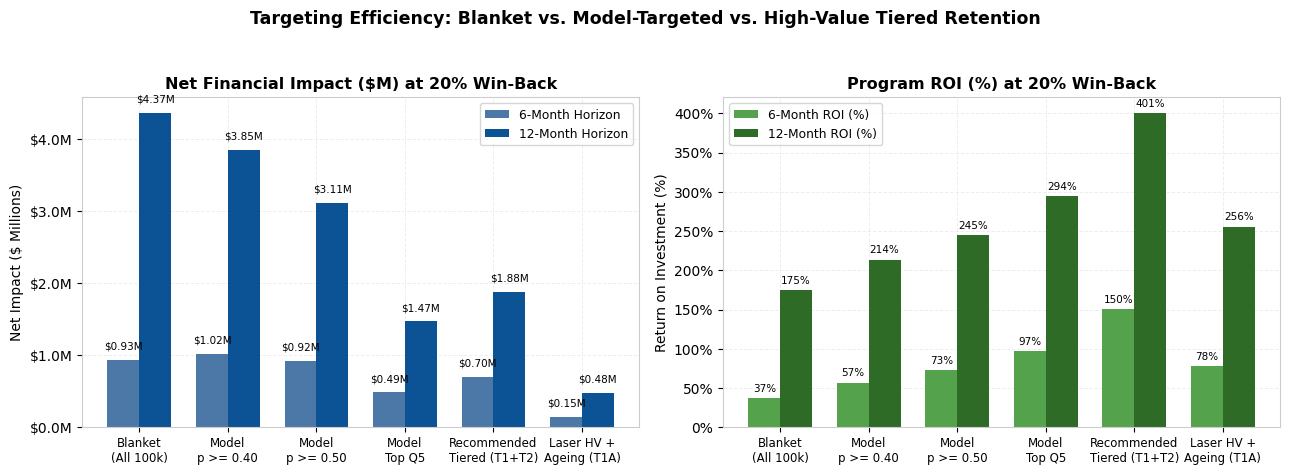

In [18]:
# Plot 10: Targeting Strategy Comparison
short_labels = ["Blanket\n(All 100k)", "Model\np >= 0.40", "Model\np >= 0.50", "Model\nTop Q5", "Recommended\nTiered (T1+T2)", "Laser HV +\nAgeing (T1A)"]
x = np.arange(len(short_labels))
w = 0.36
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.0, 4.8))
b1 = ax1.bar(x - w/2, comp_df["Net_Impact_6m"] / 1e6, width=w, color="#4C78A8", label="6-Month Horizon")
b2 = ax1.bar(x + w/2, comp_df["Net_Impact_12m"] / 1e6, width=w, color="#0B5394", label="12-Month Horizon")
ax1.set_title("Net Financial Impact ($M) at 20% Win-Back", fontsize=11.5, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(short_labels, fontsize=8.5)
ax1.set_ylabel("Net Impact ($ Millions)", fontsize=10)
ax1.yaxis.set_major_formatter(mtick.FormatStrFormatter("$%.1fM"))
ax1.legend(fontsize=8.8)
for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 0.12, f"${h:.2f}M", ha="center", va="bottom", fontsize=7.5)

r1 = ax2.bar(x - w/2, comp_df["ROI_6m_Pct"], width=w, color="#54A24B", label="6-Month ROI (%)")
r2 = ax2.bar(x + w/2, comp_df["ROI_12m_Pct"], width=w, color="#2E6B27", label="12-Month ROI (%)")
ax2.set_title("Program ROI (%) at 20% Win-Back", fontsize=11.5, fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(short_labels, fontsize=8.5)
ax2.set_ylabel("Return on Investment (%)", fontsize=10)
ax2.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.0f%%"))
ax2.legend(fontsize=8.8)
for bar in list(r1) + list(r2):
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 6, f"{h:.0f}%", ha="center", va="bottom", fontsize=7.5)
fig.suptitle("Targeting Efficiency: Blanket vs. Model-Targeted vs. High-Value Tiered Retention", fontsize=12.5, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

=== WIN-BACK RATE SENSITIVITY (RECOMMENDED PROGRAM, $468,700 COST) ===


,Win_Back_Pct,Retained_100k,Total_Cost_100k,Gross_Rev_6m,Net_Impact_6m,ROI_6m_Pct,Gross_Rev_12m,Net_Impact_12m,ROI_12m_Pct,Base_Churn_Red_pp
0,10,1326,468700.0,586576.0,117876.0,25.1,1173151.0,704451.0,150.3,1.33
1,15,1989,468700.0,879863.0,411163.0,87.7,1759727.0,1291027.0,275.4,1.99
2,20,2652,468700.0,1173151.0,704451.0,150.3,2346302.0,1877602.0,400.6,2.65
3,25,3315,468700.0,1466439.0,997739.0,212.9,2932878.0,2464178.0,525.7,3.31
4,30,3978,468700.0,1759727.0,1291027.0,275.4,3519453.0,3050753.0,650.9,3.98


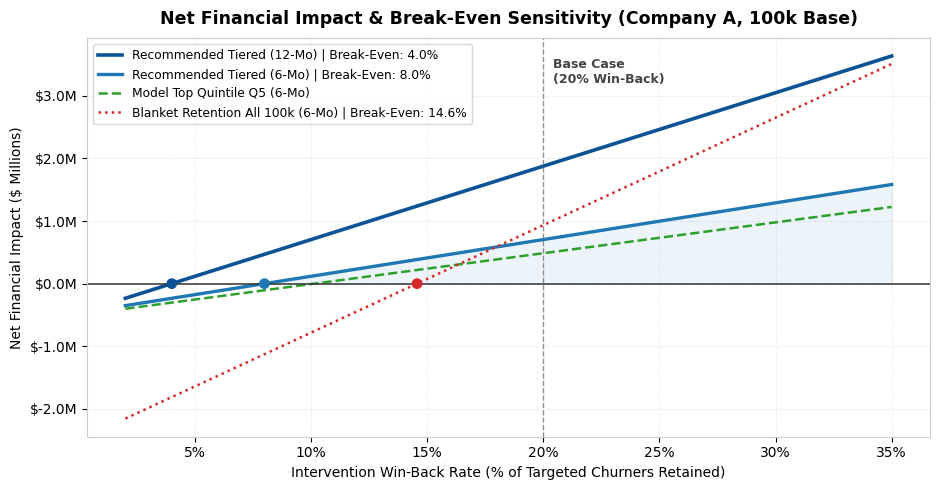

In [19]:
# Sensitivity Analysis & Break-Even Plot
sens_df = pd.DataFrame([evaluate_strategy(biz_df, "Recommended Tiered (T1+T2)", recommended_mask, tiered_cost, wb) for wb in [0.10, 0.15, 0.20, 0.25, 0.30]])
sens_df["Win_Back_Pct"] = [10, 15, 20, 25, 30]
print("=== WIN-BACK RATE SENSITIVITY (RECOMMENDED PROGRAM, $468,700 COST) ===")
display(sens_df[["Win_Back_Pct", "Retained_100k", "Total_Cost_100k", "Gross_Rev_6m", "Net_Impact_6m", "ROI_6m_Pct", "Gross_Rev_12m", "Net_Impact_12m", "ROI_12m_Pct", "Base_Churn_Red_pp"]])

wb_grid = np.linspace(0.02, 0.35, 67)
rec_net_6m = [evaluate_strategy(biz_df, "Rec", recommended_mask, tiered_cost, w)["Net_Impact_6m"] / 1e6 for w in wb_grid]
rec_net_12m = [evaluate_strategy(biz_df, "Rec", recommended_mask, tiered_cost, w)["Net_Impact_12m"] / 1e6 for w in wb_grid]
q5_net_6m = [evaluate_strategy(biz_df, "Q5", biz_df["is_q5"], 25.0, w)["Net_Impact_6m"] / 1e6 for w in wb_grid]
blk_net_6m = [evaluate_strategy(biz_df, "Blk", pd.Series(True, index=biz_df.index), 25.0, w)["Net_Impact_6m"] / 1e6 for w in wb_grid]

be_rec_6m = evaluate_strategy(biz_df, "Rec", recommended_mask, tiered_cost)["BreakEven_6m_Pct"]
be_rec_12m = evaluate_strategy(biz_df, "Rec", recommended_mask, tiered_cost)["BreakEven_12m_Pct"]
be_blk_6m = evaluate_strategy(biz_df, "Blk", pd.Series(True, index=biz_df.index), 25.0)["BreakEven_6m_Pct"]

fig, ax = plt.subplots(figsize=(9.5, 5.0))
ax.plot(wb_grid * 100, rec_net_12m, color="#0B5394", lw=2.6, label=f"Recommended Tiered (12-Mo) | Break-Even: {be_rec_12m:.1f}%")
ax.plot(wb_grid * 100, rec_net_6m, color="#1F77B4", lw=2.4, label=f"Recommended Tiered (6-Mo) | Break-Even: {be_rec_6m:.1f}%")
ax.plot(wb_grid * 100, q5_net_6m, color="#2CA02C", lw=1.8, linestyle="--", label="Model Top Quintile Q5 (6-Mo)")
ax.plot(wb_grid * 100, blk_net_6m, color="#D62728", lw=1.8, linestyle=":", label=f"Blanket Retention All 100k (6-Mo) | Break-Even: {be_blk_6m:.1f}%")
ax.axhline(0, color="#333333", lw=1.1)
ax.axvline(20.0, color="#666666", lw=1.0, linestyle="--", alpha=0.7)
ax.text(20.4, max(rec_net_12m) * 0.88, "Base Case\n(20% Win-Back)", fontsize=9, color="#444444", fontweight="bold")
ax.scatter([be_rec_12m, be_rec_6m, be_blk_6m], [0, 0, 0], color=["#0B5394", "#1F77B4", "#D62728"], zorder=5, s=45)
ax.fill_between(wb_grid * 100, 0, rec_net_6m, where=np.array(rec_net_6m) > 0, color="#1F77B4", alpha=0.08)
ax.set_title("Net Financial Impact & Break-Even Sensitivity (Company A, 100k Base)", fontsize=12.5, fontweight="bold", pad=10)
ax.set_xlabel("Intervention Win-Back Rate (% of Targeted Churners Retained)", fontsize=10)
ax.set_ylabel("Net Financial Impact ($ Millions)", fontsize=10)
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("$%.1fM"))
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter("%.0f%%"))
ax.legend(loc="upper left", frameon=True, fontsize=8.8)
plt.tight_layout()
plt.show()

### 6.4 90-Day Randomized A/B Pilot & Risk Mitigation

Before full 100k rollout, we recommend a **90-day controlled A/B pilot** on **20% of the eligible Tier 1 + Tier 2 population (`~3,868` subscribers)**:
* **Design:** `50/50` stratified split (**`1,934` Treatment** vs. **`1,934` Holdout Control**), **`$46,870` pilot budget** (`10%` of full-scale cost).
* **Pass/Fail Criteria:**
  * **Go (Full Rollout):** Treatment churn `>= 8.0 pp` lower than Control (exceeding the **`7.99%`** 6-month break-even rate) AND positive net 90-day ARPU minus offer cost.
  * **Iterate:** Win-back between `4.0%` and `7.99%` -> tighten Tier 1A trade-in cost or restrict Tier 2 to `D10` (`78.5%` churn).
  * **No-Go:** Win-back `< 4.0%` or negative net ARPU lift.

| Risk Category | Failure Mode | Mitigation Strategy |
|---|---|---|
| **Deadweight Loss** | Subsidizing `31.4%` false positives in targeted cohort | Already priced into ROI/break-even; trigger Tier 1A credits only upon customer engagement |
| **ARPU Cannibalization** | Bill credits reducing recurring revenue from heavy overage payers | Cap credits at `15%` of monthly ARPU (`$15–$25` one-time/3-mo promo); track Net ARPU in pilot |
| **Data Quality Drift** | `22%–49%` demographic missingness & negative `eqpdays`/`rev_Mean` | Rely on `>97%` complete billing/usage fields; clip `<0` anomalies with explicit flags |
| **Care Center Capacity** | Outbound Tier 1 calls causing `>10-min` wait times or `20%–25%` transfers | Route Tier 2 (`50.8%` of volume) to 100% automated SMS/app self-service; reserve live reps for Tier 1 (`~150` calls/day) |

---

### 6.5 References
1. Grand View Research. *U.S. Telecom Services Market Size, Share & Trends Analysis Report.* https://www.grandviewresearch.com/industry-analysis/us-telecom-services-market-report
2. Mordor Intelligence. *United States Telecom Market Size & Share Analysis - Growth Trends & Forecasts.* https://www.mordorintelligence.com/industry-reports/united-states-telecom-market
3. TeleGeography (2025). *2025 Mobile Market Summary.* https://resources.telegeography.com/2025-mobile-market-summary
4. PwC. *Global Telecom Outlook Perspectives.* https://www.pwc.com/gx/en/1/industries/technology-media-telecom/telecom-outlook-perspectives.html
5. The Motley Fool (2026). *America's Favorite Wireless Service: AT&T, Verizon, or T-Mobile?* https://www.fool.com/investing/2026/03/14/america-favorite-wireless-service-att-verizon-tmus/
6. ChurnCost. *Telecom Churn Rate Benchmarks & Industry Analysis.* https://churncost.com/telecom
7. Artisan Growth Strategies. *Customer Acquisition Cost vs. Retention Cost: Analysis & Benchmarks.* https://www.artisangrowthstrategies.com/blog/customer-acquisition-cost-vs-retention-cost-analysis-benchmarks
8. J.D. Power / BusinessWire (2026). *Easy to Work With, Hard to Leave: Simplicity Drives Wireless Customer Loyalty, J.D. Power Finds.* https://www.businesswire.com/news/home/20260129508649/en/Easy-to-Work-With-Hard-to-Leave-Simplicity-Drives-Wireless-Customer-Loyalty-J.D.-Power-Finds
9. Telecompetitor. *Wireless Customer Satisfaction Scores Fall, J.D. Power Report.* https://www.telecompetitor.com/wireless-customer-satisfaction-scores-fall-j-d-power-report/